In [37]:

# STEP 1: WebQAmGaze 데이터 불러오기

import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 공식 GitHub 저장소
repo = "tfnribeiro/WebQAmGaze"
folder = "scripts/pre_processed_data"

url = f"https://api.github.com/repos/{repo}/contents/{folder}"

# 파일 목록 가져오기
response = requests.get(url, timeout=30)
response.raise_for_status()
file_list = response.json()

# 영어(EN) JSON 파일만 선택
english_files = sorted(
    [
        item for item in file_list
        if item["name"].endswith(".json")
        and "_EN_" in item["name"]
    ],
    key=lambda item: item["name"]
)

# 처음 12개 파일 선택
selected_files = english_files[:12]

participants = []

# 참가자 파일 다운로드
for i, item in enumerate(selected_files, start=1):

    response = requests.get(
        item["download_url"], timeout=60
    )
    response.raise_for_status()

    person = response.json()

    # JSON 문자열로 저장된 시선 데이터 변환
    raw = person["webgazer_raw_data"]

    if isinstance(raw, str):
        raw = json.loads(raw)

    participants.append({
        "number": i,
        "filename": item["name"],
        "info": person,
        "raw": raw
    })

print("데이터 불러오기 완료!")
print("불러온 파일 수:", len(participants))

# 파일명 확인
for p in participants:
    print(p["number"], p["filename"])


데이터 불러오기 완료!
불러온 파일 수: 12
1 A10BH9PYCYUKDJ_mturk_EN_v01.json
2 A10W3EILX06DFO_mturk_EN_v20.json
3 A11C5FSSHQEQ3E_mturk_EN_v13.json
4 A11EZAV2HRYKD5_mturk_EN_v11.json
5 A11M4E3N6Q8918_mturk_EN_v08.json
6 A11YS0T8MV3Q7C_mturk_EN_v01.json
7 A12HLLXWOQJ14Q_mturk_EN_v16.json
8 A12NT768CR36E5_mturk_EN_v17.json
9 A13WTEQ06V3B6D_mturk_EN_v04.json
10 A160BYMX7X0EPG_mturk_EN_v14.json
11 A17Q4QN6UE0EZC_mturk_EN_v08.json
12 A18JFH5XQAUVAK_mturk_EN_v13.json


In [38]:

# STEP 2: 특징 추출 및 품질 점검

feature_results = []
quality_results = []

# 참가자별 분석
for p in participants:

    number = p["number"]
    person = p["info"]
    raw = p["raw"]

    # 화면 크기
    width = float(person["screen_x"])
    height = float(person["screen_y"])

    # 측정 품질 정보
    rate = float(person["webgazer_sample_rate"])
    roi = person.get("avg_roi_last_val")
    offset = person.get("avg_offset_r")

    # 과제 조건 목록
    conditions = [
        person.get(f"trial_{n}_condition")
        for n in range(10)
    ]

    # 측정 빈도 기준만 임시 검사
    quality_results.append({
        "participant": number,
        "sample_rate": rate,
        "roi_value": roi,
        "offset_r": offset,
        "NR": conditions.count("nr"),
        "IS": conditions.count("is"),
        "status": "Pass" if rate >= 10 else "Check"
    })

    # 10개 과제 분석
    for trial in range(10):

        name = person.get(f"trial_{trial}_name")
        condition = person.get(f"trial_{trial}_condition")

        if condition not in ["nr", "is"]:
            continue

        if name not in raw:
            continue

        points = raw[name]

        if isinstance(points, str):
            points = json.loads(points)

        # 시선 데이터 표 만들기
        gaze = pd.DataFrame(points)

        if gaze.empty or gaze.shape[1] != 3:
            continue

        gaze.columns = ["x", "y", "t"]

        gaze = gaze.apply(
            pd.to_numeric, errors="coerce"
        )

        # 연속 측정점의 좌표 차이
        dx = gaze["x"].diff()
        dy = gaze["y"].diff()
        dt = gaze["t"].diff()

        # 시간 간격 200ms 이하만 사용
        valid = (
            np.isfinite(dx)
            & np.isfinite(dy)
            & np.isfinite(dt)
            & (dt > 0)
            & (dt <= 200)
        )

        valid_seconds = dt[valid].sum() / 1000

        if valid_seconds <= 0:
            continue

        # 초당 가로·세로 이동량
        horizontal = dx[valid].abs().sum() / valid_seconds
        vertical = dy[valid].abs().sum() / valid_seconds

        # 결과 저장
        feature_results.append({
            "participant": number,
            "filename": p["filename"],
            "trial": trial,
            "text_id": name,
            "condition": condition.upper(),
            "horizontal_px_s": horizontal,
            "vertical_px_s": vertical,
            "horizontal_norm": horizontal / width,
            "vertical_norm": vertical / height,
            "sample_count": len(gaze),
            "valid_seconds": valid_seconds
        })

# 데이터프레임 만들기
feature_df = pd.DataFrame(feature_results)
quality_df = pd.DataFrame(quality_results)

# 참가자별 품질 결과
print("===== 참가자별 측정 품질 =====")
display(quality_df.round(2))

print("10Hz 기준 통과:",
      (quality_df["status"] == "Pass").sum())

# 처음 3개 참가자의 특징 비교
print("\n===== 처음 3개 참가자의 특징 평균 =====")

first_three = feature_df[
    feature_df["participant"] <= 3
]

summary = first_three.groupby(
    ["participant", "condition"]
)[[
    "horizontal_px_s",
    "vertical_px_s",
    "horizontal_norm",
    "vertical_norm"
]].mean()

display(summary.round(3))

print("\n전체 계산된 과제 수:", len(feature_df))


===== 참가자별 측정 품질 =====


,participant,sample_rate,roi_value,offset_r,NR,IS,status
0,1,17.02,60.65,51.97,5,5,Pass
1,2,19.82,6.36,177.26,5,5,Pass
2,3,8.12,29.22,93.70,5,5,Check
3,4,27.56,2.16,320.95,5,5,Pass
4,5,14.34,19.01,104.60,5,5,Pass
5,6,12.38,26.25,78.44,5,5,Pass
6,7,29.36,1.02,115.33,5,5,Pass
7,8,29.19,25.73,90.64,5,5,Pass
8,9,29.32,15.10,92.44,5,5,Pass
9,10,16.40,13.08,145.84,5,5,Pass


10Hz 기준 통과: 11

===== 처음 3개 참가자의 특징 평균 =====


horizontal_px_s  vertical_px_s  horizontal_norm  \
participant condition                                                    
1           IS                 559.291        314.882            0.409   
            NR                 490.711        312.000            0.359   
2           IS                2532.169       1455.072            1.391   
            NR                1885.188       1096.489            1.035   
3           IS                 740.767        543.880            0.370   
            NR                 402.429        324.105            0.201   

                       vertical_norm  
participant condition                 
1           IS                 0.410  
            NR                 0.406  
2           IS                 1.421  
            NR                 1.071  
3           IS                 0.483  
            NR                 0.288


전체 계산된 과제 수: 120


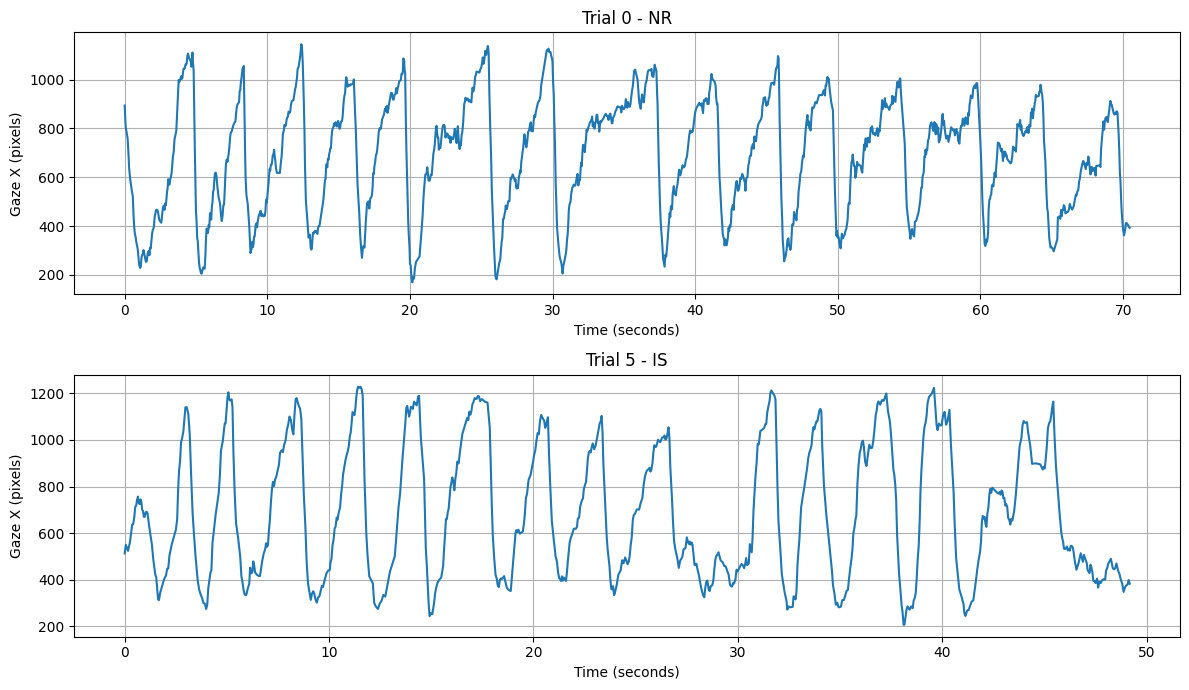

결과 저장 완료!
results/gaze_nr_is.png
results/pilot_features.csv
results/pilot_quality.csv


In [39]:

# STEP 3: 그래프 생성 및 결과 저장

from pathlib import Path

# 저장 폴더 만들기
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# 첫 번째 참가자 데이터 선택
person = participants[0]["info"]
raw = participants[0]["raw"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# NR(0번)과 IS(5번) 비교
for i, trial in enumerate([0, 5]):

    name = person[f"trial_{trial}_name"]
    condition = person[f"trial_{trial}_condition"]

    gaze = pd.DataFrame(
        raw[name], columns=["x", "y", "t"]
    )

    gaze = gaze.apply(
        pd.to_numeric, errors="coerce"
    )

    # 시간: 밀리초 -> 초
    gaze["time_s"] = (
        gaze["t"] - gaze["t"].iloc[0]
    ) / 1000

    axes[i].plot(
        gaze["time_s"],
        gaze["x"]
    )

    axes[i].set_title(
        f"Trial {trial} - {condition.upper()}"
    )

    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Gaze X (pixels)")
    axes[i].grid(True)

plt.tight_layout()

# 그래프 이미지 저장
plt.savefig(
    output_dir / "gaze_nr_is.png",
    dpi=150
)

plt.show()

# 특징 분석 결과 CSV 저장
feature_df.to_csv(
    output_dir / "pilot_features.csv",
    index=False,
    encoding="utf-8"
)

# 측정 품질 결과 CSV 저장
quality_df.to_csv(
    output_dir / "pilot_quality.csv",
    index=False,
    encoding="utf-8"
)

print("결과 저장 완료!")
print("results/gaze_nr_is.png")
print("results/pilot_features.csv")
print("results/pilot_quality.csv")
